In [1]:
import re
import os
import math

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from pandas.core.common import random_state
from sqlalchemy import create_engine

# Load variables from .env file
load_dotenv('config.env')

True

In [2]:
db_host = os.getenv("DB_HOST")
db_port = os.getenv("DB_PORT")
db_name = os.getenv("DB_NAME")
db_user = os.getenv("DB_USER")
db_pswd = os.getenv("DB_PSWD")

In [3]:
data_dir = './data'

In [4]:
# Example batch usage
batch_size = 419079
total_records = 419079
num_batches = math.ceil(total_records / batch_size)

# Define your SQLAlchemy connection parameters for `to_sql`
conn_str = f"postgresql+psycopg2://{db_user}:{db_pswd}@{db_host}:{db_port}/{db_name}"
engine = create_engine(conn_str)

In [5]:
def load_batch(limit, offset, conn):
    query = f"""
        SELECT *
        FROM vaers_data
        WHERE json_array_length(symptom_list) > 3
            AND vax_manu NOT IN ('UNKNOWN MANUFACTURER', 'NOVAVAX')
            AND vax_type = 'COVID19'
            AND vax_year <> '2020'
        ORDER BY vaers_id
        LIMIT {limit}
        OFFSET {offset}
    """
    return pd.read_sql(query, con=conn)

In [6]:
vaers_data = load_batch(batch_size, offset=0, conn=engine)
vaers_data.shape

(396563, 10)

In [7]:
vaers_data['vax_year'] = vaers_data['vax_year'].astype(int).astype(str)
vaers_data['num_symptoms'] = vaers_data['symptom_list'].apply(len)
vaers_data['report_length'] = vaers_data['symptom_text'].apply(lambda x: len([y.strip() for y in x.split(' ') if y.strip() != '' ]))

In [8]:
## Divide the reports with less than 30 words into sub-categories for rule based filtering
def sub_30_len_category(report_length):
    if 0 < report_length <= 10:
        return '<=10'
    elif 10 < report_length <= 15:
        return '11-15'
    elif 15 < report_length <= 20:
        return '16-20'
    elif 20 < report_length <= 25:
        return '20-25'
    elif 25 < report_length <= 30:
        return '26-30'
    else:
        return '30+'

vaers_data['sub_30_len_category'] = vaers_data['report_length'].apply(sub_30_len_category)
vaers_data['sub_30_len_category'].value_counts()

sub_30_len_category
30+      288258
<=10      32515
11-15     22672
16-20     19877
20-25     17295
26-30     15946
Name: count, dtype: int64

In [9]:
## Create a copy of vaers_data
vaers_data_copy = vaers_data.copy()

In [10]:
## Data with less than 10 words in the reports
vaers_data[vaers_data['sub_30_len_category'] == '<=10'].head(100)

,vaers_id,vax_type,vax_manu,vax_name,age_yrs,sex,vax_year,year,symptom_text,symptom_list,num_symptoms,report_length,sub_30_len_category
1,916604.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,47.0,F,2021,2021,"Injection site swelling, redness, warm to the ...","[Injection site erythema, Injection site pruri...",4,10,<=10
4,916617.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,35.0,F,2021,2021,"Dizziness, chills, fever, muscle aches, pain a...","[Chills, Dizziness, Injection site pain, Myalg...",5,10,<=10
11,916629.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,61.0,M,2021,2021,"Headache, chills, muscle aches and weakness","[Asthenia, Chills, Headache, Myalgia]",4,6,<=10
27,916660.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,61.0,F,2021,2021,"Body ache, head ache, fever, nausea, liwer leg...","[Headache, Muscle spasms, Nausea, Pain, Pyrexia]",5,10,<=10
33,916671.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,56.0,F,2021,2021,"Body aches, chills fever lethargy","[Chills, Lethargy, Pain, Pyrexia]",4,5,<=10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1052,918909.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,20.0,F,2021,2021,"Heart Palpitations, still on going. High feve...","[Chills, Hyperhidrosis, Palpitations, Pyrexia,...",5,10,<=10
1053,918911.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,47.0,F,2021,2021,"Temp, diarrhea for 4 hrs, malaise, bad headac...","[Diarrhoea, Headache, Insomnia, Malaise]",4,10,<=10
1068,918939.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,21.0,F,2021,2021,"Low grade fever, chills, head ache, body aches","[Chills, Headache, Pain, Pyrexia]",4,8,<=10
1083,918991.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,90.0,M,2021,2021,"Fever(101.8), muscle pain, malaise","[Full blood count, Malaise, Microbiology test,...",5,4,<=10


In [11]:
## Save the data in a file
file_path = os.path.join(data_dir, 'vaers_data_below_10.csv')
vaers_data[vaers_data['sub_30_len_category'] == '<=10'].to_csv(file_path)

# Remove the records with less than 10 words
vaers_data = vaers_data[~(vaers_data['sub_30_len_category'] == '<=10')]
vaers_data['sub_30_len_category'].value_counts()

sub_30_len_category
30+      288258
11-15     22672
16-20     19877
20-25     17295
26-30     15946
Name: count, dtype: int64

In [12]:
## Apply rule based filtering to the records with report lengths in range (10-30)
# List of temporal words and phrases categorized
plural_temporal_keywords = ['second', 'minute', 'hour', 'day', 'week', 'month', 'year', 'hr', 'min', 'sec']

non_plural_temporal_keywords = [
    'a.m.', 'p.m.', 'am', 'pm',
    'before', 'after', 'later', 'earlier', 'post',
    'spring', 'summer', 'autumn', 'winter',                                                 # Seasonal References
    'morning', 'afternoon', 'evening', 'night', 'midnight', 'noon',                         # parts of day
    'today', 'yesterday', 'tomorrow', 'now', 'then', 'fortnight',                           # Specific Time Points
    'first', 'second', 'third', 'next', 'finally', 'previously', 'initially',               # Ordinals and Sequencers
    'during', 'while', 'until', 'since', 'for', 'brief', 'prolonged', 'lasted',             # Duration Terms
    'monday', 'tuesday', 'wednesday', 'thursday','friday', 'saturday', 'sunday',            # Week Days
    'always', 'often', 'sometimes', 'frequently', 'occasionally', 'yearly', 'daily',        # Frequency Indicators
    'recently', 'soon', 'currently', 'formerly', 'simultaneously', 'lately', 'suddenly', 'gradually',     # Time-Related Adverbs
    'january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september', 'october', 'november', 'december',
    'jan', 'feb', 'mar', 'apr', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'
]

# Regex pattern to match dates in the format MM/DD/YYYY or DD/MM or MM/YYYY
date_pattern = r'\b(\d{1,2}/\d{1,2}(?:/\d{2,4})?|\d{1,2}/\d{4})\b'

# Regex pattern to match time in the format HH:MM
time_pattern = r'\b([01]?[0-9]|2[0-3]):([0-5]?[0-9])\b'

# Combine into a single pattern with proper escaping and boundaries
pattern = (
        r'\b(' + '|'.join([f'{re.escape(word)}s?' for word in plural_temporal_keywords]
                          + [re.escape(word) for word in non_plural_temporal_keywords])
        + r')\b|' + date_pattern + r'|' + time_pattern
)

# Apply the regex pattern to filter rows
vaers_data['has_temporal_info'] = vaers_data['symptom_text'].str.contains(pattern, flags=re.IGNORECASE)

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/2736613031.py:34: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  vaers_data['has_temporal_info'] = vaers_data['symptom_text'].str.contains(pattern, flags=re.IGNORECASE)


In [13]:
vaers_data.groupby(['has_temporal_info', 'sub_30_len_category'])['vaers_id'].count()

has_temporal_info  sub_30_len_category
False              11-15                   14439
                   16-20                    8059
                   20-25                    4384
                   26-30                    2635
                   30+                      5060
True               11-15                    8233
                   16-20                   11818
                   20-25                   12911
                   26-30                   13311
                   30+                    283198
Name: vaers_id, dtype: int64

In [14]:
# Save the data for manual analysis
vaers_data[(
        (~vaers_data['has_temporal_info']) &
        (vaers_data['sub_30_len_category'].isin(['11-15', '16-20', '21-25', '26-30']))
)].to_csv(os.path.join(data_dir, 'reports_without_temporal_cues_<30.csv'), index=False)

vaers_data[(
        (~vaers_data['has_temporal_info']) &
        (vaers_data['sub_30_len_category'] == '30+')
)].to_csv(os.path.join(data_dir, 'reports_without_temporal_cues_30+.csv'), index=False)

In [15]:
## Filter the records with more than 30 words or with temporal cues
vaers_data = vaers_data[(
    (vaers_data['has_temporal_info'])
    # | (vaers_data['sub_30_len_category'] == '30+')
)] ## Include only those records with temporal cues to avoid noise in the sampled data

In [16]:
vaers_data.groupby('sub_30_len_category')['vaers_id'].count()

sub_30_len_category
11-15      8233
16-20     11818
20-25     12911
26-30     13311
30+      283198
Name: vaers_id, dtype: int64

In [17]:
vaers_data.head(100)

,vaers_id,vax_type,vax_manu,vax_name,age_yrs,sex,vax_year,year,symptom_text,symptom_list,num_symptoms,report_length,sub_30_len_category,has_temporal_info
0,916602.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,23.0,F,2021,2021,"About 15 minutes after receiving the vaccine, ...","[Chest discomfort, Dysphagia, Pain in extremit...",4,73,30+,True
2,916611.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,33.0,F,2021,2021,12pm Received shot 1 pm Sore arm at injection ...,"[Blood pressure decreased, Chest pain, Chills,...",20,140,30+,True
5,916620.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,65.0,M,2021,2021,1. Sore arm started several hours later appro...,"[Arthralgia, Chills, Headache, Mobility decrea...",8,69,30+,True
6,916621.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,25.0,F,2021,2021,Fatigue - 2 hours prior. Muscle aches/pain - 3...,"[Chills, Fatigue, Headache, Myalgia]",4,26,26-30,True
7,916622.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,22.0,F,2021,2021,Felt a little nauseous and a little headache s...,"[Headache, Heart rate increased, Injection sit...",6,131,30+,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
132,916852.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,69.0,F,2021,2021,"severe chills, headache, low grade fever, join...","[Arthralgia, Chills, Headache, Injection site ...",7,79,30+,True
133,916856.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,56.0,F,2021,2021,Approximately one hour after receiving the vac...,"[Blood pressure increased, Electrocardiogram n...",4,91,30+,True
134,916857.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,65.0,M,2021,2021,Moderna COVID-19 Vaccine EUA- Received vaccin...,"[Arthralgia, Chills, Headache, Myalgia]",4,42,30+,True
135,916861.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,51.0,F,2021,2021,"continuing injection site redness, swelling, h...","[Injection site erythema, Injection site pain,...",5,13,11-15,True


In [18]:
# Create the categorized length column with ranges in the labels
bins = [0, 30, 100, 200, 500, 1000, np.inf]
labels = ['Very Short', 'Short', 'Medium', 'Long', 'Very Long', 'Extremely Long']
vaers_data['length_category'] = pd.cut(vaers_data['report_length'], bins=bins, labels=labels)

In [19]:
vaers_data.head()

,vaers_id,vax_type,vax_manu,vax_name,age_yrs,sex,vax_year,year,symptom_text,symptom_list,num_symptoms,report_length,sub_30_len_category,has_temporal_info,length_category
0,916602.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,23.0,F,2021,2021,"About 15 minutes after receiving the vaccine, ...","[Chest discomfort, Dysphagia, Pain in extremit...",4,73,30+,True,Short
2,916611.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,33.0,F,2021,2021,12pm Received shot 1 pm Sore arm at injection ...,"[Blood pressure decreased, Chest pain, Chills,...",20,140,30+,True,Medium
5,916620.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,65.0,M,2021,2021,1. Sore arm started several hours later appro...,"[Arthralgia, Chills, Headache, Mobility decrea...",8,69,30+,True,Short
6,916621.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,25.0,F,2021,2021,Fatigue - 2 hours prior. Muscle aches/pain - 3...,"[Chills, Fatigue, Headache, Myalgia]",4,26,26-30,True,Very Short
7,916622.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,22.0,F,2021,2021,Felt a little nauseous and a little headache s...,"[Headache, Heart rate increased, Injection sit...",6,131,30+,True,Medium


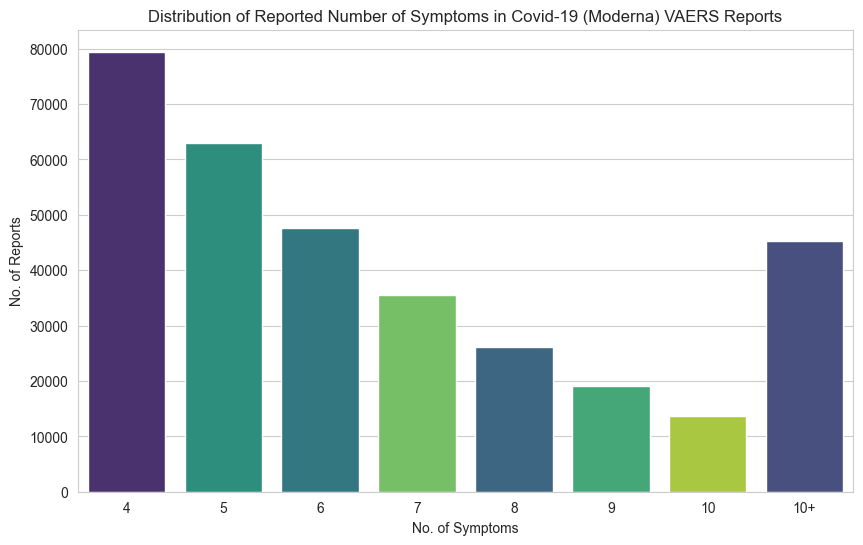

In [20]:
vaers_data['num_symptom_str'] = vaers_data['num_symptoms'].apply(lambda x: '10+' if x > 10 else str(x))

# Define the correct order for the x-axis labels, including '10+' at the end
order = [str(i) for i in range(4, 11)] + ['10+']

# Plotting the bar chart
plt.figure(figsize=(10, 6))
sns.countplot(data=vaers_data, x='num_symptom_str', palette="viridis", order=order, hue='num_symptom_str', legend=False)

# Adding labels and title
plt.xlabel("No. of Symptoms")
plt.ylabel("No. of Reports")
plt.title("Distribution of Reported Number of Symptoms in Covid-19 (Moderna) VAERS Reports")
plt.xticks(rotation=0)
plt.show()

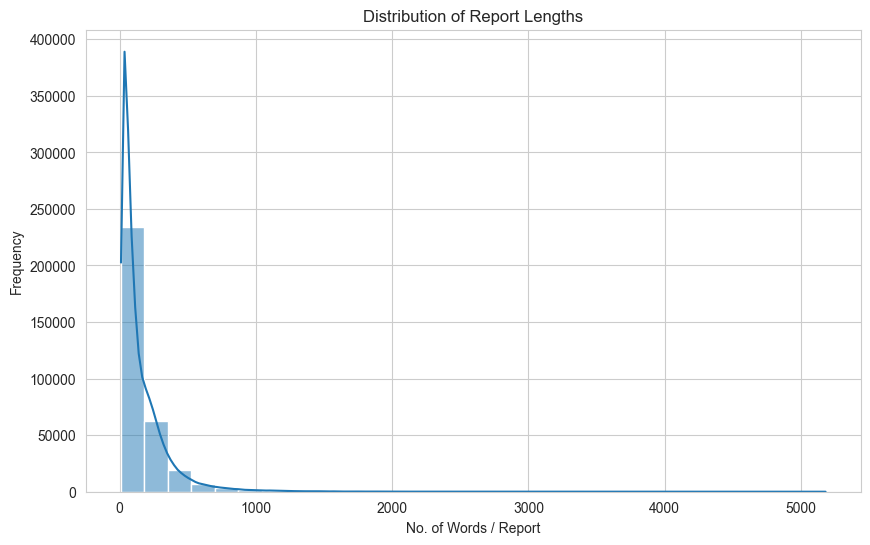

In [21]:
## Histogram of Report Lengths
plt.figure(figsize=(10, 6))
sns.histplot(vaers_data['report_length'], bins=30, kde=True)
plt.xlabel("No. of Words / Report")
plt.ylabel("Frequency")
plt.title("Distribution of Report Lengths")
plt.show()

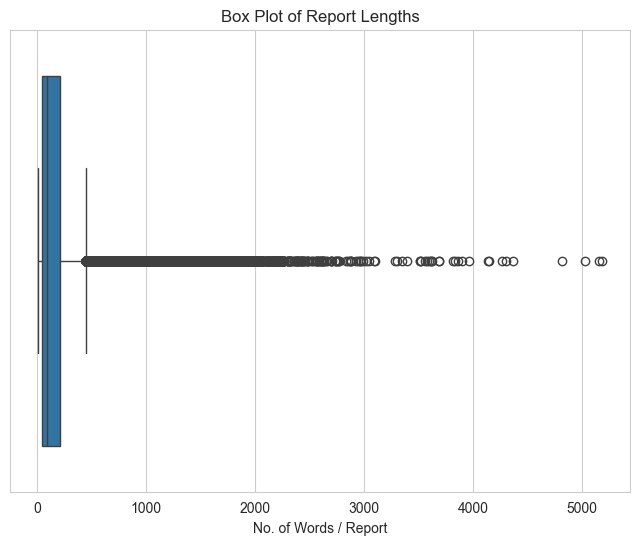

In [22]:
# Box Plot of Report Lengths
plt.figure(figsize=(8, 6))
sns.boxplot(x=vaers_data['report_length'])
plt.xlabel("No. of Words / Report")
plt.title("Box Plot of Report Lengths")
plt.show()

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/553365795.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  bar_plot.set_xticklabels(custom_labels)


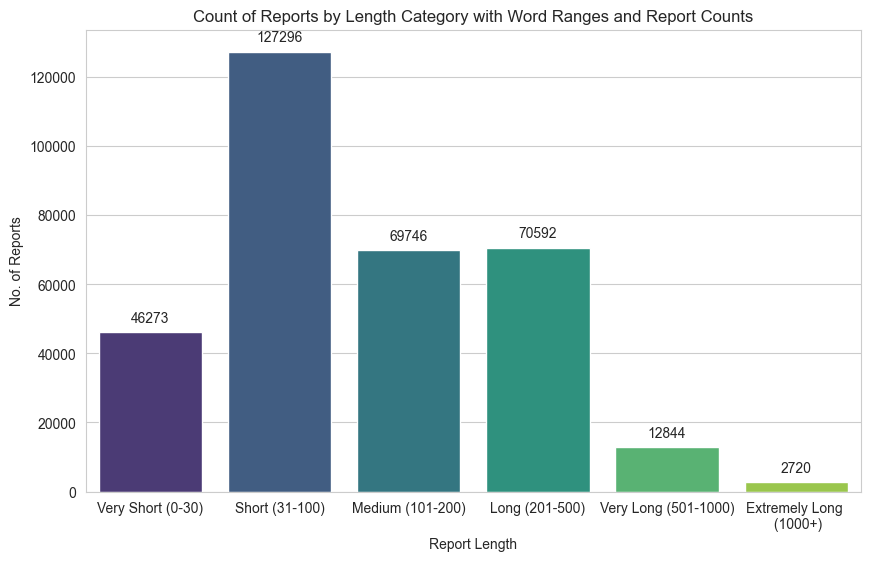

In [23]:
plt.figure(figsize=(10, 6))
bar_plot = sns.countplot(
    data=vaers_data,
    x='length_category',
    palette='viridis',
    legend=False,
    hue='length_category'
)

# Set custom x-axis labels including word ranges
custom_labels = [
    'Very Short (0-30)',
    'Short (31-100)',
    'Medium (101-200)',
    'Long (201-500)',
    'Very Long (501-1000)',
    'Extremely Long \n (1000+)'
]
bar_plot.set_xticklabels(custom_labels)

# Adding annotations on top of each bar with the total number of reports
category_counts = vaers_data['length_category'].value_counts(sort=False).values
for p, count in zip(bar_plot.patches, category_counts):
    bar_plot.annotate(f'{int(count)}',
                      (p.get_x() + p.get_width() / 2., p.get_height()),  # Position at center of each bar
                      ha='center', va='bottom',  # Center alignment
                      xytext=(0, 5), textcoords='offset points')  # Offset by 5 points above bar

# Adding labels and title
plt.xlabel("Report Length")
plt.ylabel("No. of Reports")
plt.title("Count of Reports by Length Category with Word Ranges and Report Counts")
plt.show()

## Sampling Data:

In [24]:
## Create separate dataframes for each vaccine
pfizer_data = vaers_data[vaers_data['vax_manu'].str.strip() == 'PFIZER\BIONTECH']
moderna_data = vaers_data[vaers_data['vax_manu'].str.strip() == 'MODERNA']
janssen_data = vaers_data[vaers_data['vax_manu'].str.strip() == 'JANSSEN']

In [25]:
random_state = 42
vac_sample_size = 2000
sampling_vars = ['length_category','vax_year']

pfizer_frac = 2050/pfizer_data.shape[0]
moderna_frac = 2050/moderna_data.shape[0]
janssen_frac = 2050/janssen_data.shape[0]

In [26]:
## Sample 3000 records for each vaccine
s_pfizer_data = pfizer_data.groupby(
    sampling_vars, group_keys=False
).apply(lambda x: x.sample(frac=pfizer_frac, random_state=random_state), include_groups=True)
fs_pfizer_data = s_pfizer_data.sample(n=vac_sample_size, random_state=random_state)

s_moderna_data = moderna_data.groupby(
    sampling_vars, group_keys=False
).apply(lambda x: x.sample(frac=moderna_frac, random_state=random_state), include_groups=True)
fs_moderna_data = s_moderna_data.sample(n=vac_sample_size, random_state=random_state)

s_janssen_data = janssen_data.groupby(
    sampling_vars, group_keys=False
).apply(lambda x: x.sample(frac=janssen_frac, random_state=random_state), include_groups=True)
fs_janssen_data = s_janssen_data.sample(n=vac_sample_size, random_state=random_state)

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/2565739803.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  s_pfizer_data = pfizer_data.groupby(
/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/2565739803.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  s_pfizer_data = pfizer_data.groupby(
/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/2565739803.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future ve

In [27]:
sampled_data = pd.concat([fs_pfizer_data, fs_moderna_data, fs_janssen_data], ignore_index=True)

In [28]:
sampled_data.vax_manu.value_counts()

vax_manu
PFIZER\BIONTECH                             2000
MODERNA                                     2000
JANSSEN                                     2000
Name: count, dtype: int64

In [29]:
sampled_data = sampled_data[[
    'vaers_id', 'vax_type', 'vax_manu', 'age_yrs', 'sex', 'vax_year', 'symptom_text',
    'symptom_list', 'num_symptoms', 'report_length', 'length_category'
]]

In [30]:
sampled_data.head()

,vaers_id,vax_type,vax_manu,age_yrs,sex,vax_year,symptom_text,symptom_list,num_symptoms,report_length,length_category
0,1518165.0,COVID19,PFIZER\BIONTECH,NaN,F,2021,Thyroiditis subacute; Arthralgia; Headache; Ly...,"[Arthralgia, Headache, Lymphadenopathy, Pyrexi...",5,175,Medium
1,1323125.0,COVID19,PFIZER\BIONTECH,59.0,F,2021,"Chills, Fever 102 for 3 days, body aches, head...","[Chills, Headache, Pain, Pyrexia]",4,24,Very Short
2,1824196.0,COVID19,PFIZER\BIONTECH,22.0,F,2021,Headache; Nausea; Severe pain in arms/legs (fe...,"[Fatigue, Headache, Nausea, Pain, Pain in extr...",6,382,Long
3,1229461.0,COVID19,PFIZER\BIONTECH,30.0,F,2021,I had my first dose of Covid 19 Pfizer vaccine...,"[Angiogram, Asthenia, Blood count normal, Bloo...",16,340,Long
4,2562412.0,COVID19,PFIZER\BIONTECH,63.0,M,2023,"On January 16, 2022 I experienced what turned ...","[Computerised tomogram, Dizziness, Foot deform...",9,122,Medium


In [31]:
file_path = os.path.join(data_dir, 'sampled_data.csv')
sampled_data.to_csv(file_path, index=False)

In [32]:
pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / pfizer_data.shape[0] * 100

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/1784706039.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / pfizer_data.shape[0] * 100


length_category  vax_year
Very Short       2021        10.233442
                 2022         1.862360
                 2023         0.512251
                 2024         0.173702
Short            2021        27.750114
                 2022         7.146993
                 2023         1.444793
                 2024         0.497265
Medium           2021        15.686328
                 2022         3.900465
                 2023         0.645082
                 2024         0.262256
Long             2021        17.558224
                 2022         4.890227
                 2023         0.792899
                 2024         0.386232
Very Long        2021         3.081000
                 2022         1.452286
                 2023         0.311302
                 2024         0.136237
Extremely Long   2021         0.693446
                 2022         0.396450
                 2023         0.123976
                 2024         0.062669
Name: vaers_id, dtype: float64

In [33]:
fs_pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / fs_pfizer_data.shape[0] * 100

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_91579/1544963066.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fs_pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / fs_pfizer_data.shape[0] * 100


length_category  vax_year
Very Short       2021        10.25
                 2022         1.90
                 2023         0.50
                 2024         0.20
Short            2021        27.75
                 2022         7.05
                 2023         1.50
                 2024         0.50
Medium           2021        15.55
                 2022         3.95
                 2023         0.65
                 2024         0.20
Long             2021        17.55
                 2022         4.95
                 2023         0.75
                 2024         0.40
Very Long        2021         3.15
                 2022         1.45
                 2023         0.30
                 2024         0.15
Extremely Long   2021         0.70
                 2022         0.40
                 2023         0.15
                 2024         0.05
Name: vaers_id, dtype: float64